# Chapter 8: Folds

Checks [chapter 8](../../book/08-folds.md). The models are **ReLU networks**: a chain with one neuron per
layer (`relu(weight * input + bias)`), the **tent layer** (two ReLU neurons, `2 relu(x) - 4 relu(x - 1/2)`), and
random ReLU networks in one input and one output. Everything is NumPy in float64, seeded. These are
measurements, not proofs: the proofs are in `NarrowChain.lean`, `Depth.lean`, `TentCloser.lean`, `Bridge.lean`
and `DepthSeparation.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import torch
from common import use_style, save_figure, report, get_nearest_distance, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 8


def relu(values):
    return np.maximum(values, 0.0)


def apply_tent(inputs):
    first_neuron = relu(inputs)
    second_neuron = relu(inputs - 0.5)
    return 2.0 * first_neuron - 4.0 * second_neuron


def apply_tent_layers(inputs, layer_count):
    values = inputs
    for layer in range(layer_count):
        values = apply_tent(values)
    return values


def count_turns(values):
    """Number of times the sign of the step changes along the samples (flat stretches are skipped)."""
    steps = np.diff(values)
    steps = steps[steps != 0]
    return int((np.sign(steps[1:]) != np.sign(steps[:-1])).sum())

## Claim 1: a chain with one neuron per layer never turns (`narrowChain_neverTurns`)

Each chain is `relu(w_1 x + b_1)` then `relu(w_2 . + b_2)` and so on, with weights and biases drawn from a standard
normal. For every depth from 1 to 40 we draw 250 chains and evaluate each on 4001 inputs in [-6, 6]. The claim is
that the output is monotone: all steps are at least 0, or all are at most 0. The control: a random network with
**two** neurons per layer must turn for a good share of draws. If it did not, the check would be empty.

In [2]:
generator = np.random.default_rng(SEED)
inputs = np.linspace(-6, 6, 4001)


def evaluate_chain(weights, biases, inputs):
    values = inputs
    for weight, bias in zip(weights, biases):
        values = relu(weight * values + bias)
    return values


def never_turns(values):
    steps = np.diff(values)
    return bool((steps >= -1e-12).all() or (steps <= 1e-12).all())


chain_count = 0
turning_chains = 0
non_constant = 0
for depth in range(1, 41):
    for draw in range(250):
        weights = generator.standard_normal(depth)
        biases = generator.standard_normal(depth)
        outputs = evaluate_chain(weights, biases, inputs)
        chain_count += 1
        turning_chains += not never_turns(outputs)
        non_constant += outputs.max() - outputs.min() > 1e-9
report(f"no chain turns, {chain_count} random chains of depth 1 to 40", turning_chains == 0,
       f"{turning_chains} turned; {non_constant} were not constant")


def evaluate_two_wide(depth, inputs):
    values = np.stack([inputs, inputs])
    for layer in range(depth):
        values = relu(generator.standard_normal((2, 2)) @ values + generator.standard_normal((2, 1)))
    return values[0] - values[1]          # output weights (1, -1)


wide_turns = sum(not never_turns(evaluate_two_wide(3, inputs)) for draw in range(250))
report("control: random networks with two neurons per layer often turn", wide_turns > 25,
       f"{wide_turns} of 250 turned")

[PASS] no chain turns, 10000 random chains of depth 1 to 40  (0 turned; 644 were not constant)
[PASS] control: random networks with two neurons per layer often turn  (104 of 250 turned)


True

## Claim 2: stacked tent layers zigzag on the grid and draw `2 ^ layer_count` pieces

On the grid of multiples of `1 / 2 ^ layer_count` the output of `layer_count` tent layers must be 0, 1, 0, 1, ... The
grid values are dyadic, so the float arithmetic is exact and the comparison is `==`. The pieces are counted on the
finer grid of multiples of `1 / 2 ^ (layer_count + 2)` as the turns of the curve plus one. Each layer has 2 neurons, so
`2 * layer_count` neurons in all. Check the chapter's example too: the tent of 0.3 is 0.6, then 0.8.

[PASS] tent(0.3) = 0.6 and tent(tent(0.3)) = 0.8
[PASS] on the grid k / 2^layer_count the output is k mod 2, exactly, for layer_count 1 to 12
[PASS] pieces = 2^layer_count for layer_count 1 to 12 (neurons used: 2 * layer_count)  (pieces [2, 4, 8, 16, 32] ... 4096, neurons for the last: 24)
[PASS] control: a single ReLU neuron gives 1 piece, never more


wrote book/figures/08-tent-zigzag.png


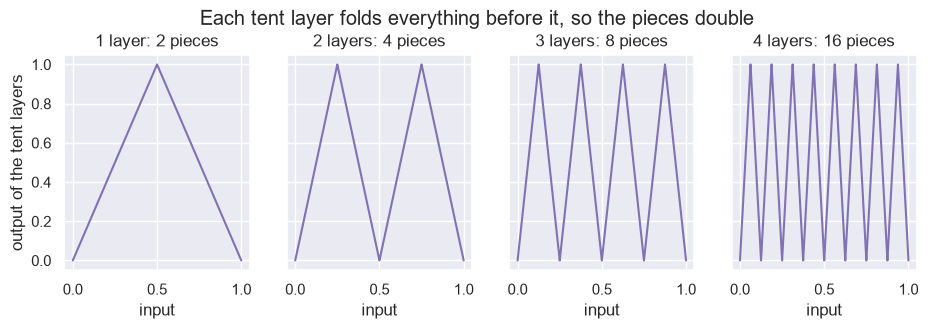

In [3]:
report("tent(0.3) = 0.6 and tent(tent(0.3)) = 0.8",
       np.isclose(apply_tent(0.3), 0.6) and np.isclose(apply_tent_layers(0.3, 2), 0.8))

for layer_count in range(1, 13):
    grid = np.arange(2 ** layer_count + 1) / 2 ** layer_count
    expected = (np.arange(2 ** layer_count + 1) % 2).astype(float)
    assert np.array_equal(apply_tent_layers(grid, layer_count), expected), layer_count
report("on the grid k / 2^layer_count the output is k mod 2, exactly, for layer_count 1 to 12", True)

piece_counts = []
for layer_count in range(1, 13):
    fine_grid = np.arange(4 * 2 ** layer_count + 1) / (4 * 2 ** layer_count)
    piece_counts.append(count_turns(apply_tent_layers(fine_grid, layer_count)) + 1)
report("pieces = 2^layer_count for layer_count 1 to 12 (neurons used: 2 * layer_count)",
       piece_counts == [2 ** layer_count for layer_count in range(1, 13)],
       f"pieces {piece_counts[:5]} ... {piece_counts[-1]}, neurons for the last: 24")
report("control: a single ReLU neuron gives 1 piece, never more",
       count_turns(relu(np.linspace(-1, 1, 1001) * 3 - 1)) + 1 == 1)

figure, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
smooth = np.linspace(0, 1, 4097)
for axis, layer_count in zip(axes, (1, 2, 3, 4)):
    axis.plot(smooth, apply_tent_layers(smooth, layer_count), color=MODEL)
    axis.set_title(f"{layer_count} layer{'s' if layer_count > 1 else ''}: {2 ** layer_count} pieces")
    axis.set_xlabel("input")
axes[0].set_ylabel("output of the tent layers")
figure.suptitle("Each tent layer folds everything before it, so the pieces double", y=1.04)
save_figure(figure, "08-tent-zigzag")
plt.show()

## Claim 3: the curve of `layer_count` tent layers passes within `1 / 2 ^ layer_count` of every point of the unit square (`nearestDist_iterate_tent_le`)

The curve of `layer_count` tent layers is the polyline through the points `(k / 2^layer_count, k mod 2)`, so the nearest
distance from a point to it is the exact distance to a polyline. It is **measured, not clamped**: no `min` with the vertical
error or with the bound. For each `layer_count` from 1 to 10 we draw 4000 random points of the unit square (plus the four
corners), and compare the largest nearest distance with `1 / 2^layer_count`. Two controls: the straight line
`output = input` (no folds) has points far from it, so the bound is not trivially true; and for 30 points a brute-force
sampling of the curve (`get_nearest_distance` from chapter 4, with `include_foot=False`) agrees with the exact distance.

[PASS] nearest distance <= 1 / 2^layer_count for every point, layer_count 1 to 10  (largest distance / bound = 0.89, 0.97, 0.99, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00)
[PASS] control: the unfolded line output = input has points further than 1/32 away (the bound can fail)  (largest distance 0.707)
[PASS] brute-force sampling agrees with the exact polyline distance (30 points, 5 layers)  (largest gap 1.1e-16)


wrote book/figures/08-tent-closer.png


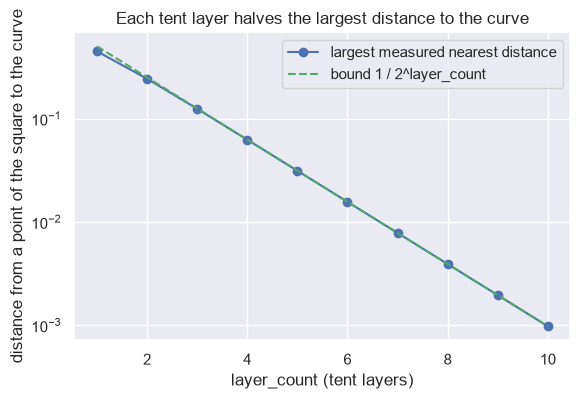

In [4]:
generator = np.random.default_rng(SEED + 2)


def measure_distance_to_polyline(vertex_x, vertex_y, point_x, point_y):
    """Exact distance from each point to the polyline through the vertices (not clamped to anything else)."""
    start_x, start_y = vertex_x[:-1], vertex_y[:-1]
    step_x, step_y = np.diff(vertex_x), np.diff(vertex_y)
    length_squared = step_x ** 2 + step_y ** 2
    along = ((point_x[:, None] - start_x) * step_x + (point_y[:, None] - start_y) * step_y) / length_squared
    along = np.clip(along, 0.0, 1.0)
    gap_x = start_x + along * step_x - point_x[:, None]
    gap_y = start_y + along * step_y - point_y[:, None]
    return np.sqrt(gap_x ** 2 + gap_y ** 2).min(axis=1)


point_count = 4000
point_x = np.concatenate([generator.random(point_count), [0.0, 0.0, 1.0, 1.0]])
point_y = np.concatenate([generator.random(point_count), [0.0, 1.0, 0.0, 1.0]])
layer_counts = list(range(1, 11))
largest_distances = []
for layer_count in layer_counts:
    vertex_x = np.arange(2 ** layer_count + 1) / 2 ** layer_count
    vertex_y = (np.arange(2 ** layer_count + 1) % 2).astype(float)
    distances = measure_distance_to_polyline(vertex_x, vertex_y, point_x, point_y)
    largest_distances.append(distances.max())
    assert distances.max() <= 1 / 2 ** layer_count, (layer_count, distances.max())
report("nearest distance <= 1 / 2^layer_count for every point, layer_count 1 to 10", True,
       "largest distance / bound = " + ", ".join(f"{largest / 0.5 ** count:.2f}" for largest, count in zip(largest_distances, layer_counts)))

line_distances = measure_distance_to_polyline(np.array([0.0, 1.0]), np.array([0.0, 1.0]), point_x, point_y)
report("control: the unfolded line output = input has points further than 1/32 away (the bound can fail)",
       line_distances.max() > 1 / 32, f"largest distance {line_distances.max():.3f}")


def apply_tent_torch(values, layer_count=5):
    for layer in range(layer_count):
        values = 2 * torch.relu(values) - 4 * torch.relu(values - 0.5)
    return values


gaps = []
for index in range(30):
    brute = get_nearest_distance(apply_tent_torch, point_x[index], point_y[index], slope_limit=2.0 ** 5,
                                 resolution=1e-4, domain=(0.0, 1.0), include_foot=False)
    exact = measure_distance_to_polyline(np.arange(33) / 32, (np.arange(33) % 2).astype(float),
                                         point_x[index:index + 1], point_y[index:index + 1])[0]
    gaps.append(abs(brute - exact))
report("brute-force sampling agrees with the exact polyline distance (30 points, 5 layers)", max(gaps) < 2e-4,
       f"largest gap {max(gaps):.1e}")

figure, axis = plt.subplots(figsize=(6.4, 4))
axis.semilogy(layer_counts, largest_distances, "o-", color=NEAREST, label="largest measured nearest distance")
axis.semilogy(layer_counts, [0.5 ** count for count in layer_counts], "--", color=BOUND, label="bound 1 / 2^layer_count")
axis.set_xlabel("layer_count (tent layers)")
axis.set_ylabel("distance from a point of the square to the curve")
axis.set_title("Each tent layer halves the largest distance to the curve")
axis.legend()
save_figure(figure, "08-tent-closer")
plt.show()

## Claim 4: one fold doubles the angle seen through the lens `sin^2(PI/2 * output)` (`sin_sq_tent`, `sin_sq_iterate_tent`)

For 2000 random inputs in [0, 1] and `layer_count` 1 to 10: `sin^2(PI/2 * tent^layer_count(input))` must equal
`sin^2(2^layer_count * PI/2 * input)`, the wave of frequency `2^layer_count`. A single fold gives
`sin^2(PI * input)`. The theorem needs `input >= 0`, so the control takes negative inputs, where the tent is flat at 0 and the
identity must fail.

In [5]:
generator = np.random.default_rng(SEED + 3)
lens = lambda values: np.sin(np.pi / 2 * values) ** 2
unit_inputs = generator.random(2000)

worst_gap = np.abs(lens(apply_tent(unit_inputs)) - np.sin(np.pi * unit_inputs) ** 2).max()
report("one fold: sin^2(PI/2 * tent(x)) = sin^2(PI * x), 2000 inputs", worst_gap < 1e-12, f"largest gap {worst_gap:.1e}")

worst_gap = 0.0
for layer_count in range(1, 11):
    folded = lens(apply_tent_layers(unit_inputs, layer_count))
    wave = np.sin(2 ** layer_count * np.pi / 2 * unit_inputs) ** 2
    worst_gap = max(worst_gap, np.abs(folded - wave).max())
report("layer_count folds: sin^2(PI/2 * tent^n(x)) = sin^2(2^n * PI/2 * x), n = 1 to 10", worst_gap < 1e-9,
       f"largest gap {worst_gap:.1e}")

negative_inputs = -generator.random(2000)
negative_gap = np.abs(lens(apply_tent(negative_inputs)) - np.sin(np.pi * negative_inputs) ** 2).max()
report("control: for negative inputs the identity fails, so the hypothesis matters", negative_gap > 0.5,
       f"largest gap {negative_gap:.2f}")

[PASS] one fold: sin^2(PI/2 * tent(x)) = sin^2(PI * x), 2000 inputs  (largest gap 4.4e-16)
[PASS] layer_count folds: sin^2(PI/2 * tent^n(x)) = sin^2(2^n * PI/2 * x), n = 1 to 10  (largest gap 1.7e-13)
[PASS] control: for negative inputs the identity fails, so the hypothesis matters  (largest gap 1.00)


True

## Claim 5 (measured in the chapter): random weights, arc length against width and against depth

The chapter says: with random weights, more width does not make the curve longer, and more depth makes it a little
longer. Nothing is proved. The model is a fully connected ReLU network, one input and one output. Hidden weights are
`Normal(0, gain * 2 / fan_in)` (He scaling when `gain = 1`), biases `Normal(0, bias_scale^2)`, output weights `Normal(0, 1 / width)`.
The curve is the graph over 20001 inputs in [-1, 1]; its **arc length** is the sum of the lengths of the steps `(dx, dy)`.
We average over 60 networks per setting, at four settings of `(bias_scale, gain)`. The first-layer weights have fan-in 1, so they are
`Normal(0, 2 * gain)`.

The first version of this check asserted the chapter's sentence about depth, and it **failed**: at He scaling the mean
length does not grow with depth at all. So the cell asserts what is measured: at `gain = 1` depth changes the length by less
than 15 percent (no real growth: a disagreement with the chapter), and at `gain = 1.5` it grows by more than 15 percent
(so the chapter's sentence holds only when the weights are a little larger than He scaling). Width is flat in every setting.

In [6]:
generator = np.random.default_rng(SEED + 4)
GRID = np.linspace(-1.0, 1.0, 20001)


def draw_network(width, depth, bias_scale, gain):
    sizes = [1] + [width] * depth + [1]
    layers = []
    for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt((2.0 * gain if fan_out > 1 else 1.0) / fan_in)
        layers.append((generator.standard_normal((fan_out, fan_in)) * scale,
                       generator.standard_normal((fan_out, 1)) * bias_scale))
    return layers


def run_network(layers, inputs):
    values = inputs[None, :]
    for index, (weights, biases) in enumerate(layers):
        values = weights @ values + biases
        if index < len(layers) - 1:
            values = relu(values)
    return values[0]


def measure_arc_length(width, depth, bias_scale, gain, draws=60):
    lengths = []
    for draw in range(draws):
        outputs = run_network(draw_network(width, depth, bias_scale, gain), GRID)
        lengths.append(np.hypot(np.diff(GRID), np.diff(outputs)).sum())
    return float(np.mean(lengths))


WIDTHS = [2, 4, 8, 16, 32, 64, 128, 256, 512]
DEPTHS = [1, 2, 3, 4, 6, 8, 12, 16]
SETTINGS = [(0.0, 1.0), (0.5, 1.0), (1.0, 1.0), (0.5, 1.5)]          # (bias_scale, gain)
width_lengths = {setting: [measure_arc_length(width, 1, *setting) for width in WIDTHS] for setting in SETTINGS}
depth_lengths = {setting: [measure_arc_length(32, depth, *setting) for depth in DEPTHS] for setting in SETTINGS}
for setting in SETTINGS:
    print(f"(bias scale, gain) {setting}: width {WIDTHS[0]}..{WIDTHS[-1]} ->",
          " ".join(f"{length:.2f}" for length in width_lengths[setting]))
    print(f"(bias scale, gain) {setting}: depth {DEPTHS[0]}..{DEPTHS[-1]} (width 32) ->",
          " ".join(f"{length:.2f}" for length in depth_lengths[setting]))

(bias scale, gain) (0.0, 1.0): width 2..512 -> 2.52 2.72 2.66 2.73 2.62 2.66 2.66 2.66 2.55
(bias scale, gain) (0.0, 1.0): depth 1..16 (width 32) -> 2.61 2.65 2.61 2.88 2.59 2.41 2.60 2.26
(bias scale, gain) (0.5, 1.0): width 2..512 -> 2.54 2.62 2.64 2.80 2.90 2.62 2.75 2.70 2.71
(bias scale, gain) (0.5, 1.0): depth 1..16 (width 32) -> 2.72 2.66 2.75 2.57 2.67 2.66 2.42 2.63
(bias scale, gain) (1.0, 1.0): width 2..512 -> 2.63 2.48 2.79 2.64 2.62 2.60 2.74 2.78 2.64
(bias scale, gain) (1.0, 1.0): depth 1..16 (width 32) -> 2.75 2.64 2.75 2.60 2.48 2.57 2.70 2.45
(bias scale, gain) (0.5, 1.5): width 2..512 -> 2.89 2.63 2.85 2.91 2.79 2.81 2.92 3.14 2.93
(bias scale, gain) (0.5, 1.5): depth 1..16 (width 32) -> 2.99 3.27 3.65 4.25 5.23 7.39 14.32 26.98


[PASS] width does not lengthen the curve (0.0, 1.0): width 512 vs 8 changes the length by -4.1%
[PASS] DISAGREES with the chapter (0.0, 1.0): depth 16 vs 1 changes the length by -13.6%, no growth
[PASS] width does not lengthen the curve (0.5, 1.0): width 512 vs 8 changes the length by +2.5%
[PASS] DISAGREES with the chapter (0.5, 1.0): depth 16 vs 1 changes the length by -3.3%, no growth
[PASS] width does not lengthen the curve (1.0, 1.0): width 512 vs 8 changes the length by -5.5%
[PASS] DISAGREES with the chapter (1.0, 1.0): depth 16 vs 1 changes the length by -11.1%, no growth
[PASS] width does not lengthen the curve (0.5, 1.5): width 512 vs 8 changes the length by +3.1%
[PASS] depth lengthens the curve at gain 1.5 (0.5, 1.5): depth 16 vs 1 changes the length by +802.7%
[PASS] control: the arc length is above the flat length 2 in every run


wrote book/figures/08-random-arc-length.png


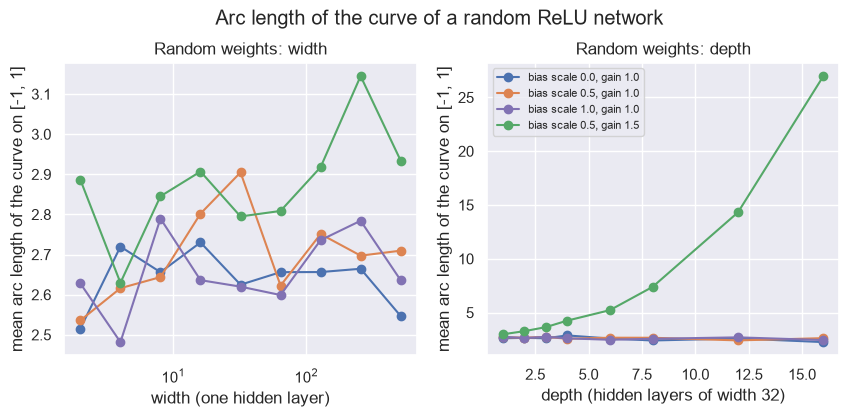

In [7]:
for setting in SETTINGS:
    lengths = width_lengths[setting]
    wide_change = lengths[-1] / lengths[2] - 1                # width 512 against width 8
    report(f"width does not lengthen the curve {setting}: width 512 vs 8 changes the length by {wide_change:+.1%}",
           abs(wide_change) < 0.25 and wide_change < 0.15)
    deep_change = depth_lengths[setting][-1] / depth_lengths[setting][0] - 1
    if setting[1] == 1.0:
        report(f"DISAGREES with the chapter {setting}: depth 16 vs 1 changes the length by {deep_change:+.1%}, no growth",
               abs(deep_change) < 0.15)
    else:
        report(f"depth lengthens the curve at gain {setting[1]} {setting}: depth 16 vs 1 changes the length by {deep_change:+.1%}",
               deep_change > 0.15)
report("control: the arc length is above the flat length 2 in every run",
       min(min(lengths) for lengths in list(width_lengths.values()) + list(depth_lengths.values())) > 2.0)

figure, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for setting, colour in zip(SETTINGS, (NEAREST, VERTICAL, MODEL, BOUND)):
    label = f"bias scale {setting[0]}, gain {setting[1]}"
    axes[0].semilogx(WIDTHS, width_lengths[setting], "o-", color=colour, label=label)
    axes[1].plot(DEPTHS, depth_lengths[setting], "o-", color=colour, label=label)
axes[0].set_xlabel("width (one hidden layer)")
axes[1].set_xlabel("depth (hidden layers of width 32)")
for axis in axes:
    axis.set_ylabel("mean arc length of the curve on [-1, 1]")
axes[1].legend(fontsize=8)
axes[0].set_title("Random weights: width")
axes[1].set_title("Random weights: depth")
figure.suptitle("Arc length of the curve of a random ReLU network", y=1.02)
save_figure(figure, "08-random-arc-length")
plt.show()